In [ ]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

import pandas as pd

from statsforecast.models import (
    CrostonClassic as Croston,
)
from statsforecast.models import (
    DynamicOptimizedTheta as DOT,
)
from statsforecast.models import (
    HistoricAverage,
    HoltWinters,
    SeasonalNaive,
)

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mse

In [ ]:
# importing the dataset
df = pd.read_csv(
    "https://datasets-nixtla.s3.amazonaws.com/air-passengers.csv", parse_dates=["ds"]
)
df.head()

Note: you may need to restart the kernel to use updated packages.


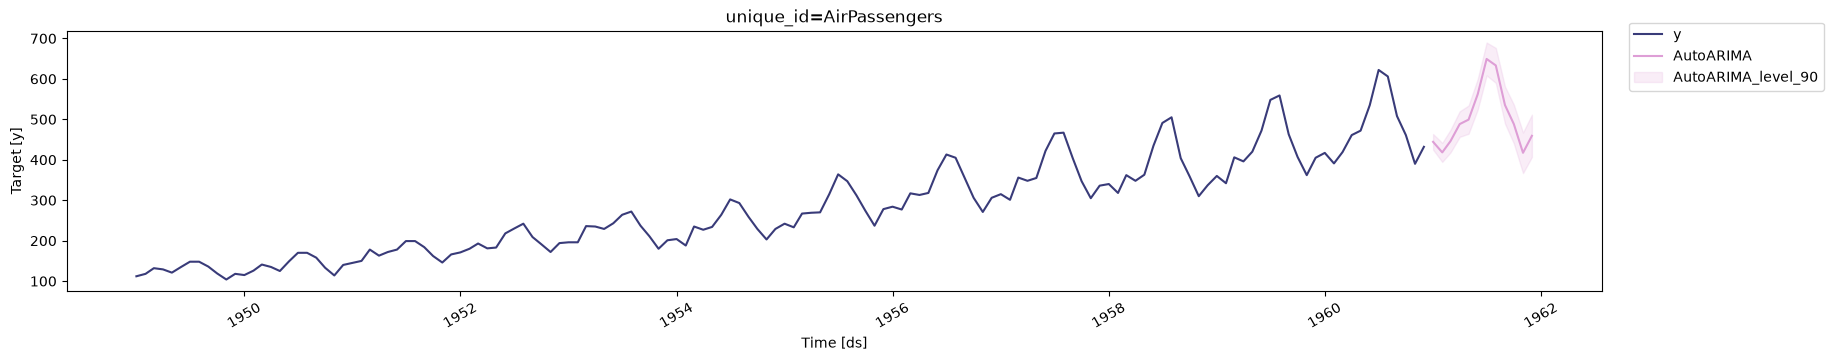

In [47]:
# this is the fitted model
sf = StatsForecast(
    models=[AutoARIMA(season_length=12)],
    freq="MS",
)
sf.fit(df)
# this is the predicted model
forecast_df = sf.predict(
    h=12, level=[90]
)  # forecasts the next 12 months with a prediction interval of 90%
forecast_df.tail()

# plot the forecast
sf.plot(df, forecast_df, level=[90])

In [ ]:
# End to End Walkthrough

Y_df = pd.read_parquet("https://datasets-nixtla.s3.amazonaws.com/m4-hourly.parquet")
Y_df.head()

# shrinking the dataset and selecting 10 ids so the example runs quicker
uids = Y_df["unique_id"].unique()[:10]
Y_df = Y_df.query("unique_id in @uids")
Y_df = Y_df.groupby("unique_id").tail(
    7 * 24
)  # select last 7 days of data to make example faster

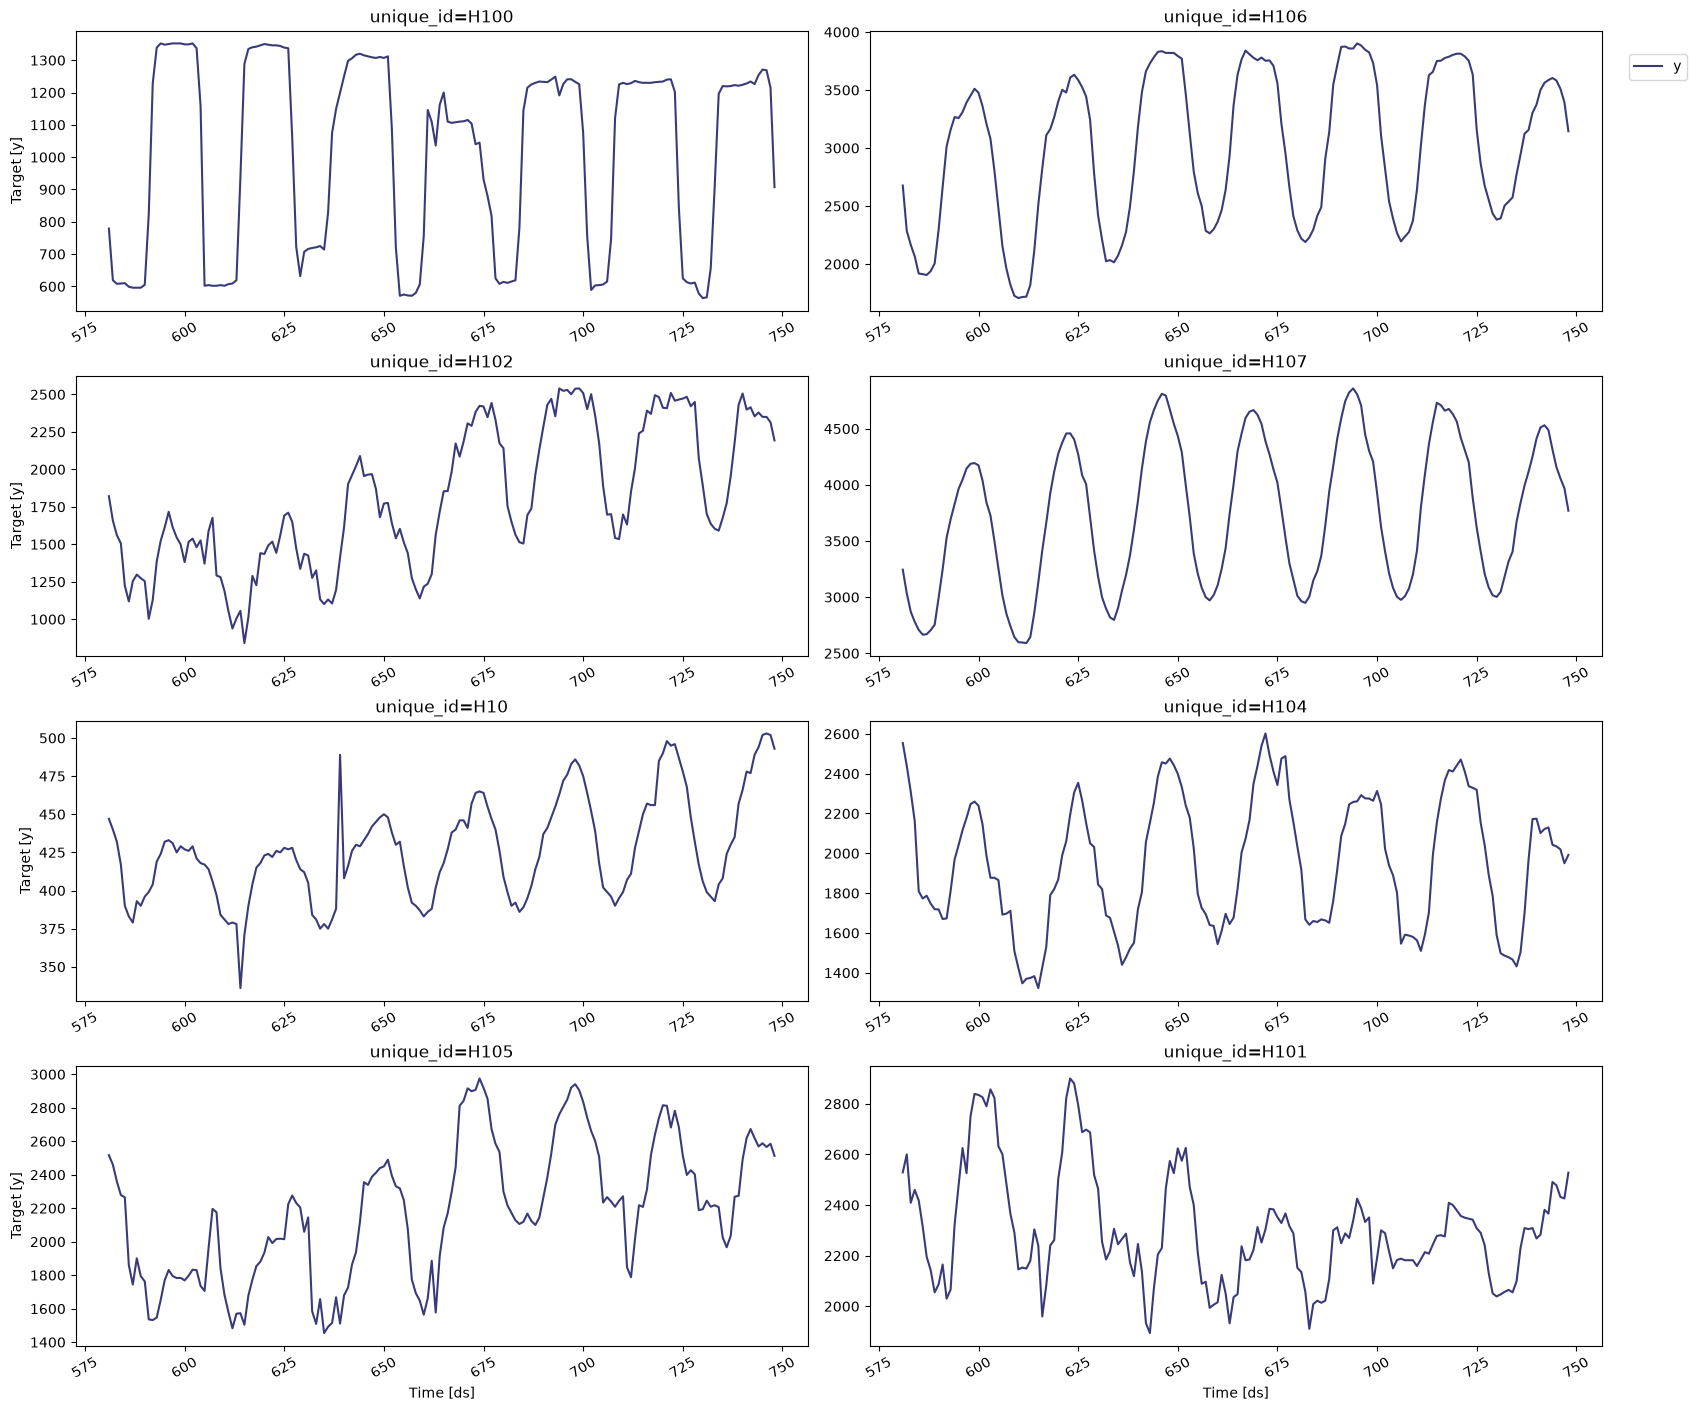

In [49]:
# explore the data by plotting it
StatsForecast.plot(Y_df)

In [ ]:
# train multiple models for many series
# importing and instantiating the models

# create a list of models and instantiation parameters so that you can compare forecasting models
models = [
    HoltWinters(),
    Croston(),
    SeasonalNaive(season_length=24),
    HistoricAverage(),
    DOT(season_length=24),
]

# instantiate StatsForecast class as sf
sf = StatsForecast(  # creates the StatsForecast object
    models=models,  # list of models to fit
    freq=1,
    fallback_model=SeasonalNaive(season_length=7),
    n_jobs=-1,
)
forecasts_df = sf.forecast(df=Y_df, h=48, level=[90])
forecasts_df.head()

,unique_id,ds,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90,CrostonClassic,CrostonClassic-lo-90,CrostonClassic-hi-90,SeasonalNaive,SeasonalNaive-lo-90,SeasonalNaive-hi-90,HistoricAverage,HistoricAverage-lo-90,HistoricAverage-hi-90,DynamicOptimizedTheta,DynamicOptimizedTheta-lo-90,DynamicOptimizedTheta-hi-90
0,H1,749,829.0,422.549268,1235.450732,829.0,422.549268,1235.450732,635.0,566.036734,703.963266,660.982143,398.037761,923.926524,592.701851,577.868889,608.544851
1,H1,750,807.0,400.549268,1213.450732,807.0,400.549268,1213.450732,572.0,503.036734,640.963266,660.982143,398.037761,923.926524,525.589117,507.067586,542.003077
2,H1,751,785.0,378.549268,1191.450732,785.0,378.549268,1191.450732,532.0,463.036734,600.963266,660.982143,398.037761,923.926524,489.251814,464.326266,513.317400
3,H1,752,756.0,349.549268,1162.450732,756.0,349.549268,1162.450732,493.0,424.036734,561.963266,660.982143,398.037761,923.926524,456.195032,429.196146,479.903788
4,H1,753,719.0,312.549268,1125.450732,719.0,312.549268,1125.450732,477.0,408.036734,545.963266,660.982143,398.037761,923.926524,436.290514,408.406558,463.537048


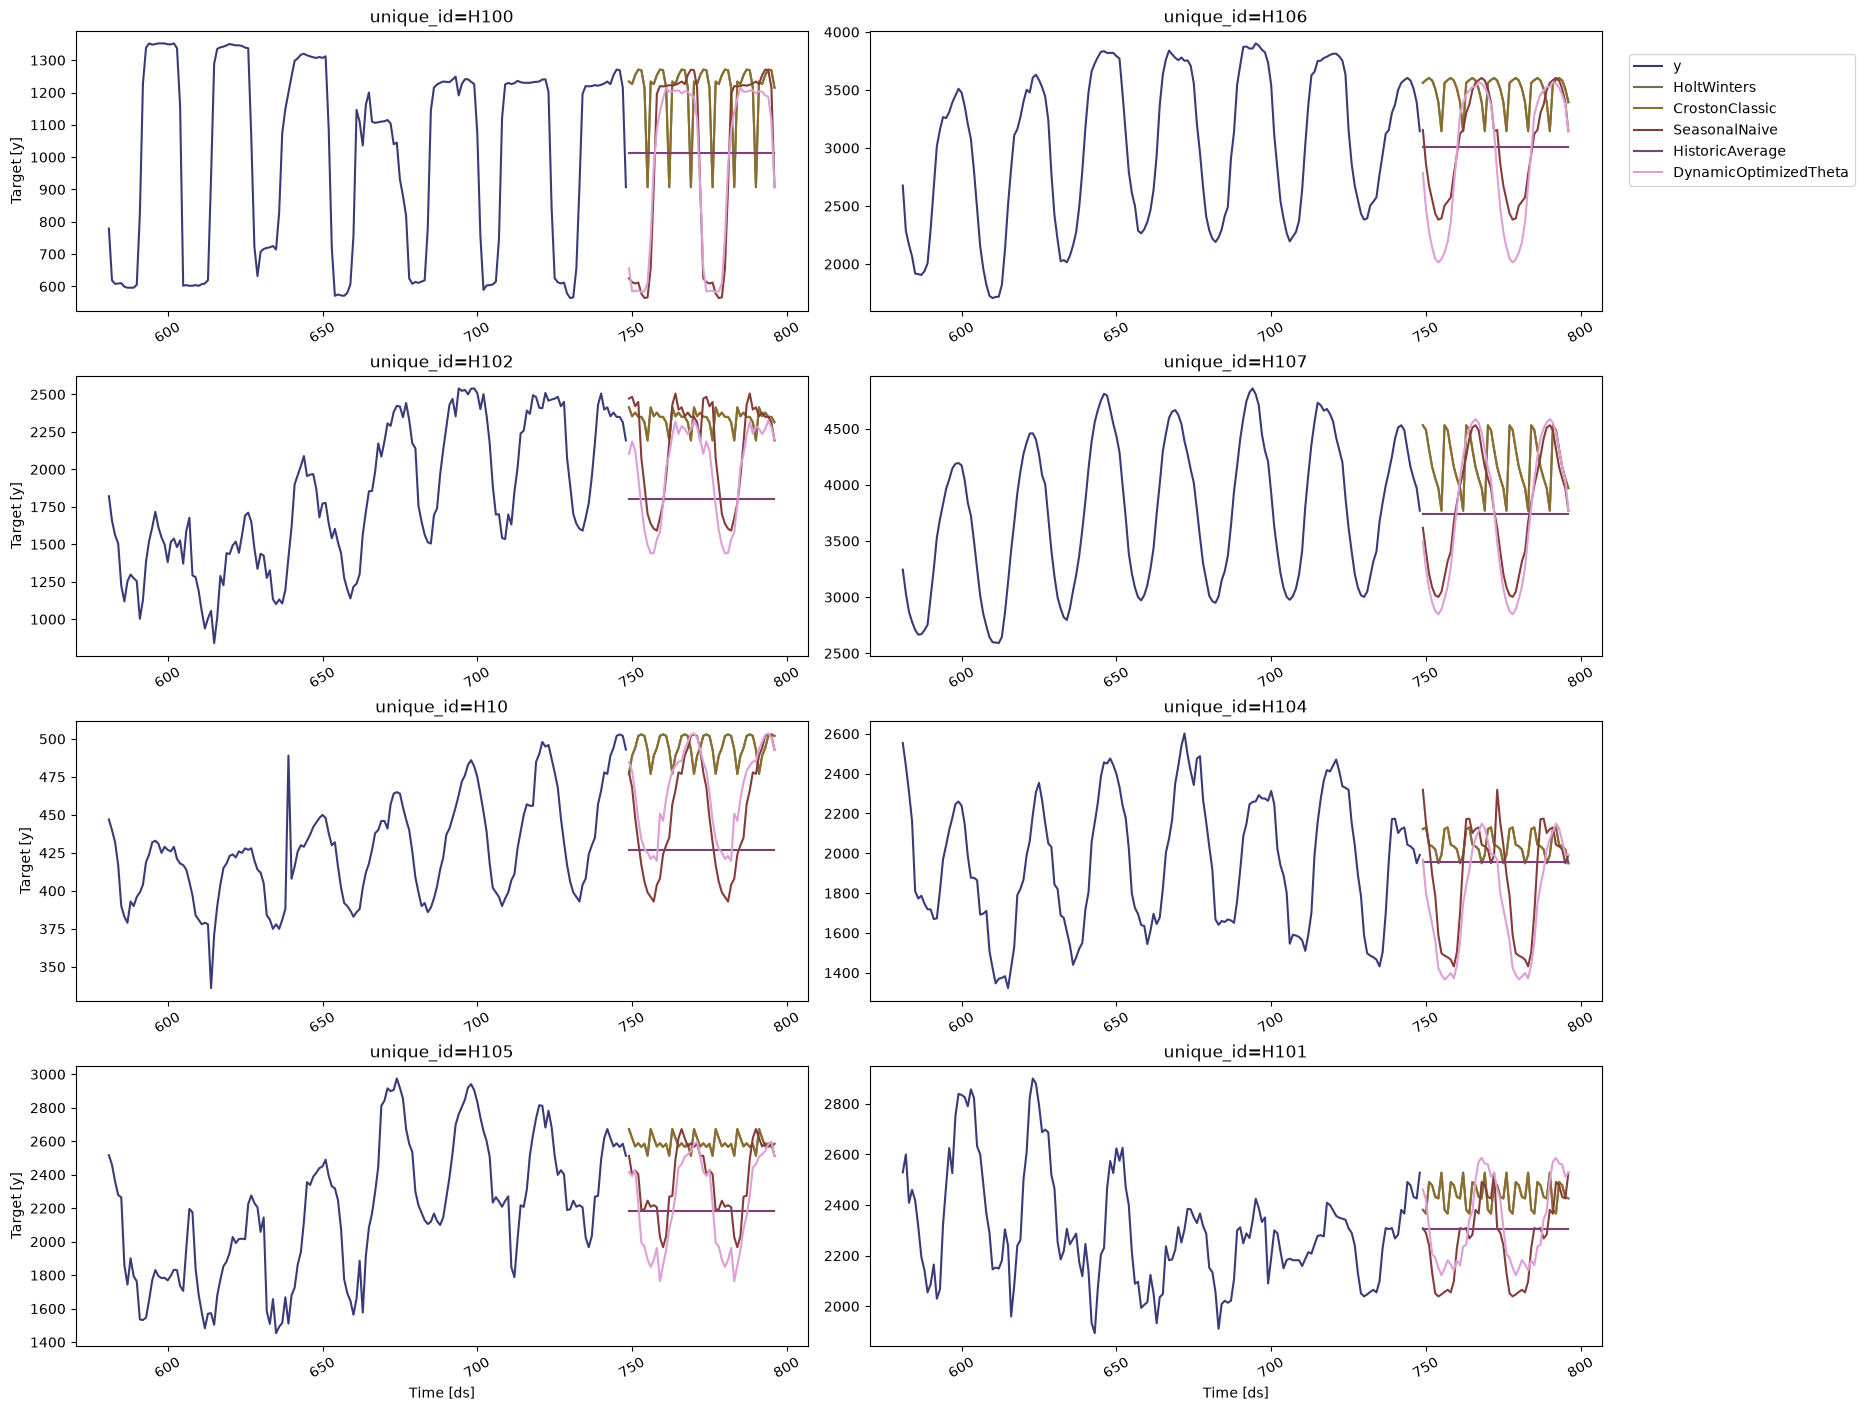

In [51]:
sf.plot(Y_df, forecasts_df)

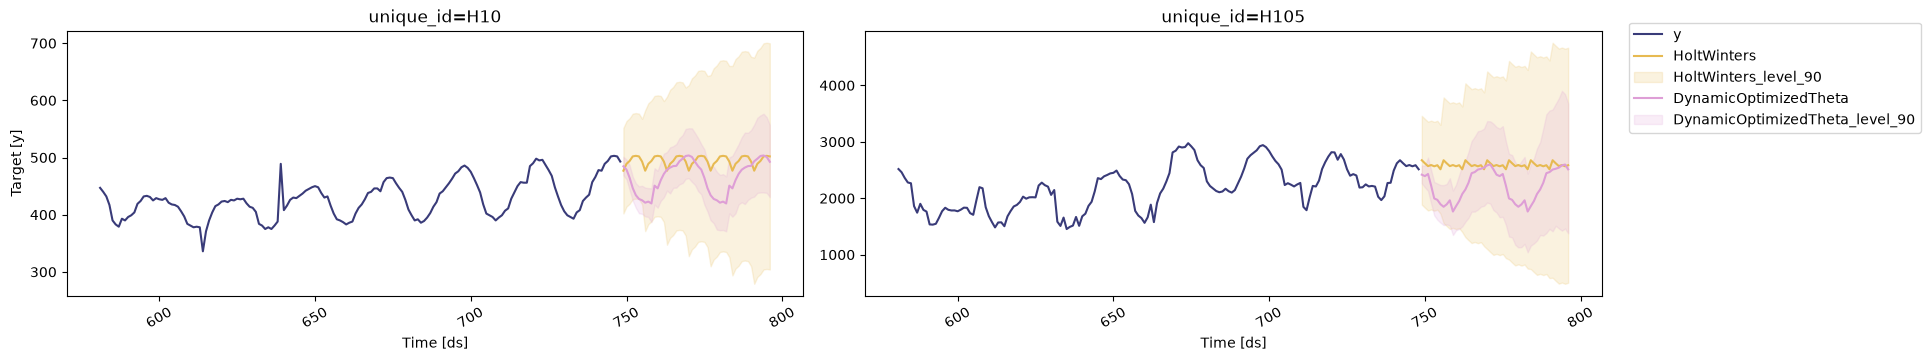

In [52]:
# customising the plots through plotting to unique_ids and some selected models
sf.plot(
    Y_df,
    forecasts_df,
    models=["HoltWinters", "DynamicOptimizedTheta"],
    unique_ids=["H10", "H105"],
    level=[90],
)  # plots only H10 and H105 with only two models and the 90% prediction

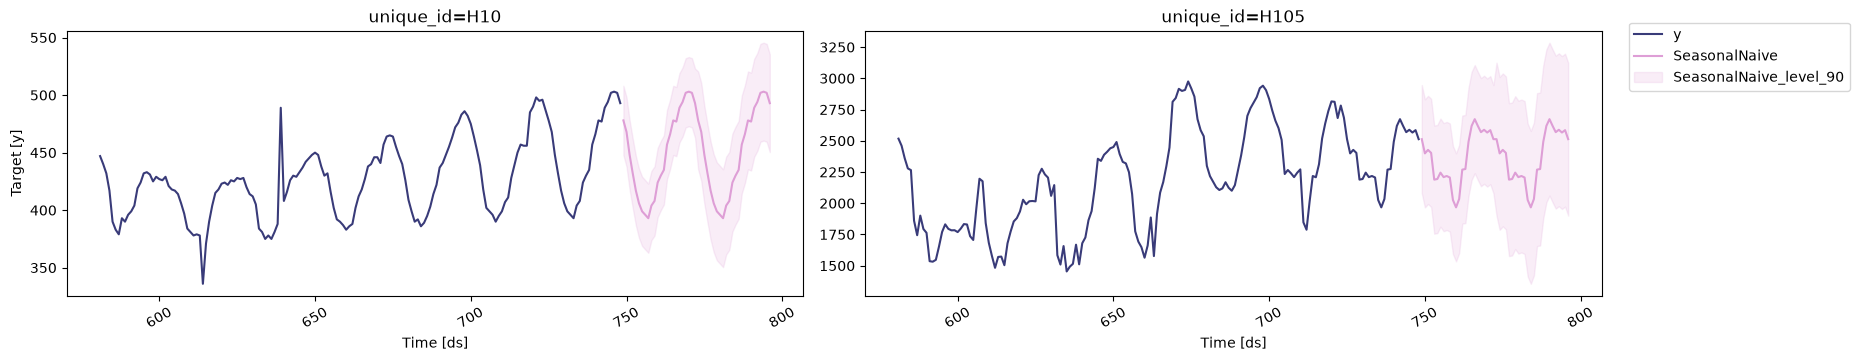

In [53]:
# exploring other models
sf.plot(
    Y_df, forecasts_df, models=["SeasonalNaive"], unique_ids=["H10", "H105"], level=[90]
)

In [54]:
# cross-validating the models
cv_df = sf.cross_validation(  # runs cross-validation and stores the result in a new dataframe
    df=Y_df,  # this is the training data
    h=24,  # this forecasts 24 hours ahead in each window
    step_size=24,  # moves the window forward 24 steps between each forecast run
    n_windows=2,  # evaluates 2 windows so there are 2 forecasting runs in the past
)

cv_df.head()

,unique_id,ds,cutoff,y,HoltWinters,CrostonClassic,SeasonalNaive,HistoricAverage,DynamicOptimizedTheta
0,H1,701,700,619.0,847.0,742.668748,691.0,661.675,612.767525
1,H1,702,700,565.0,820.0,742.668748,618.0,661.675,536.846296
2,H1,703,700,532.0,790.0,742.668748,563.0,661.675,497.824302
3,H1,704,700,495.0,784.0,742.668748,529.0,661.675,464.723235
4,H1,705,700,481.0,752.0,742.668748,504.0,661.675,440.972351


In [ ]:
# this scores each models cross-validation forecasts and picks the best one per series
def evaluate_cv(
    df, metric
):  # takes the cross-validation dataframe and an error metric function (ie. mean square error)
    models = df.columns.drop(
        ["unique_id", "ds", "y", "cutoff"]
    ).tolist()  # removes non-model columns
    evals = evaluate(
        df, metrics=[metric], models=models
    )  # computes the metric for each series and model
    evals = evals.drop(
        columns=["metric"]
    )  # removes the column holding the metrics name
    evals["best_model"] = evals[models].idxmin(
        axis=1
    )  # adds a column with the name of the model that has the lowest error in each row
    return evals  # returns the table of per-series errors plus the best model


# create a dataframe with the results of evaluation of your cross-validation df using MSE
evaluation_df = evaluate_cv(cv_df, mse)
evaluation_df.head()

# create a summary table with model column and the number of series where that model performs best
evaluation_df["best_model"].value_counts().to_frame().reset_index()

,best_model,count
0,SeasonalNaive,11
1,DynamicOptimizedTheta,8
2,CrostonClassic,1


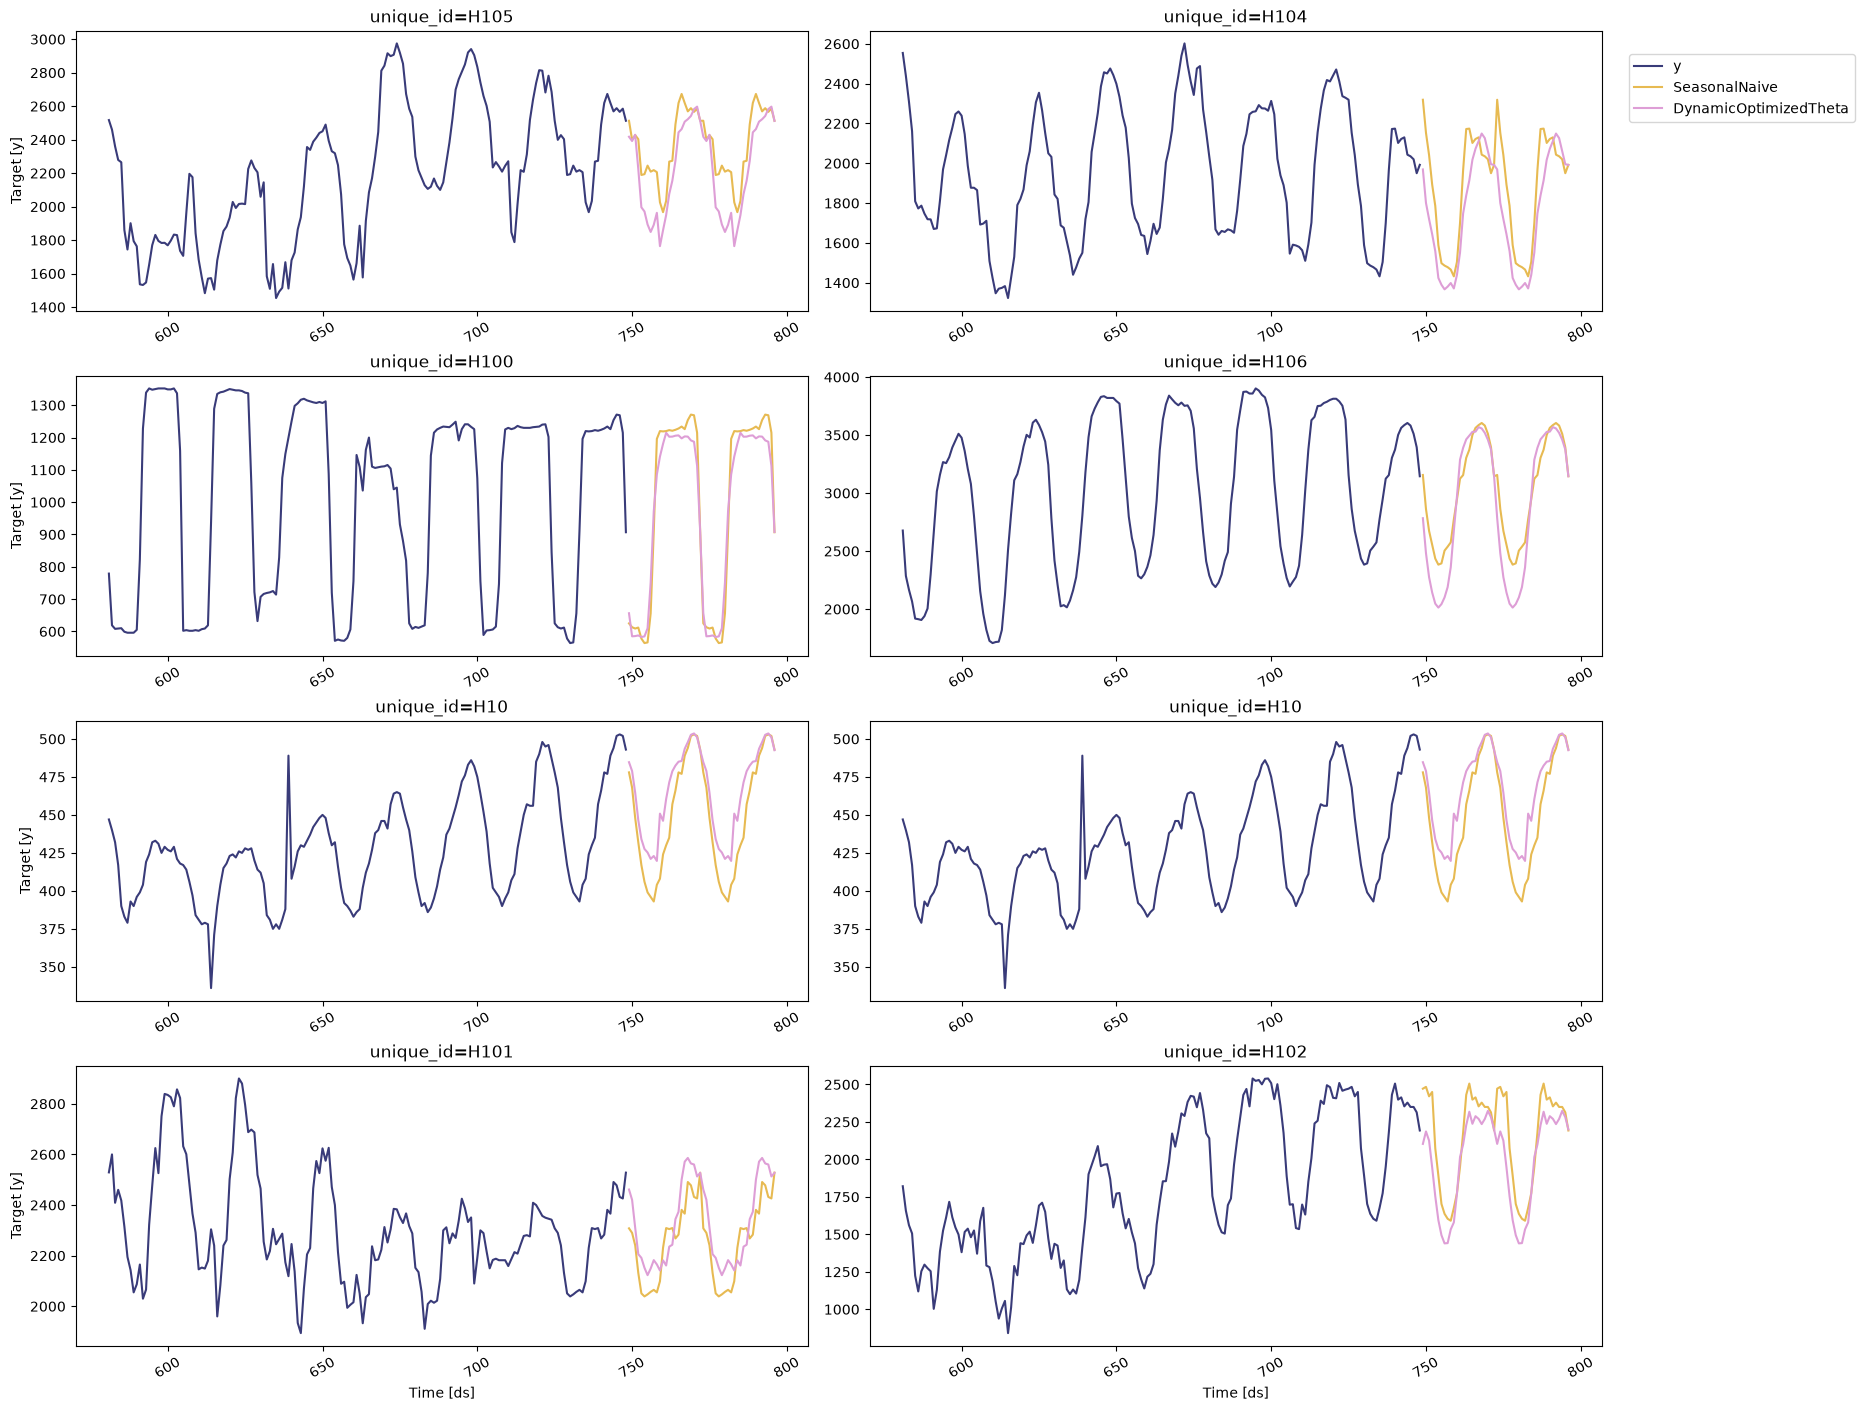

In [35]:
# plot the unique_ids where a specific model wins
seasonal_ids = evaluation_df.query('best_model == "SeasonalNaive"')[
    "unique_id"
]  # keeps the unique_ids where seasonalnaive had the best result
sf.plot(
    Y_df,
    forecasts_df,
    unique_ids=seasonal_ids,
    models=["SeasonalNaive", "DynamicOptimizedTheta"],
)  # plots the historical data and forecasts for only these series for comparison

In [ ]:
# making a dataframe with best possible forecast for every unique_id
def get_best_model_forecast(forecasts_df, evaluation_df):  # defines the function
    with_best = forecasts_df.merge(
        evaluation_df[["unique_id", "best_model"]]
    )  # merges the best model name into the forecasts
    res = with_best[
        ["unique_id", "ds"]
    ].copy()  # creates a 'res' copy which only keeps unique id and the timestamp
    for suffix in ("", "-lo-90", "-hi-90"):  # loops over the 3 columns
        res[f"best_model{suffix}"] = with_best.apply(
            lambda row: row[row["best_model"] + suffix], axis=1
        )  # this creates a column where for each row it adds the suffic to get column name (ie. AutoARIMA-lo-90)
    return res


prod_forecasts_df = get_best_model_forecast(forecasts_df, evaluation_df)
prod_forecasts_df.head()

,unique_id,ds,best_model,best_model-lo-90,best_model-hi-90
0,H1,749,635.000000,566.036734,703.963266
1,H1,749,592.701851,577.868889,608.544851
2,H1,750,572.000000,503.036734,640.963266
3,H1,750,525.589117,507.067586,542.003077
4,H1,751,532.000000,463.036734,600.963266


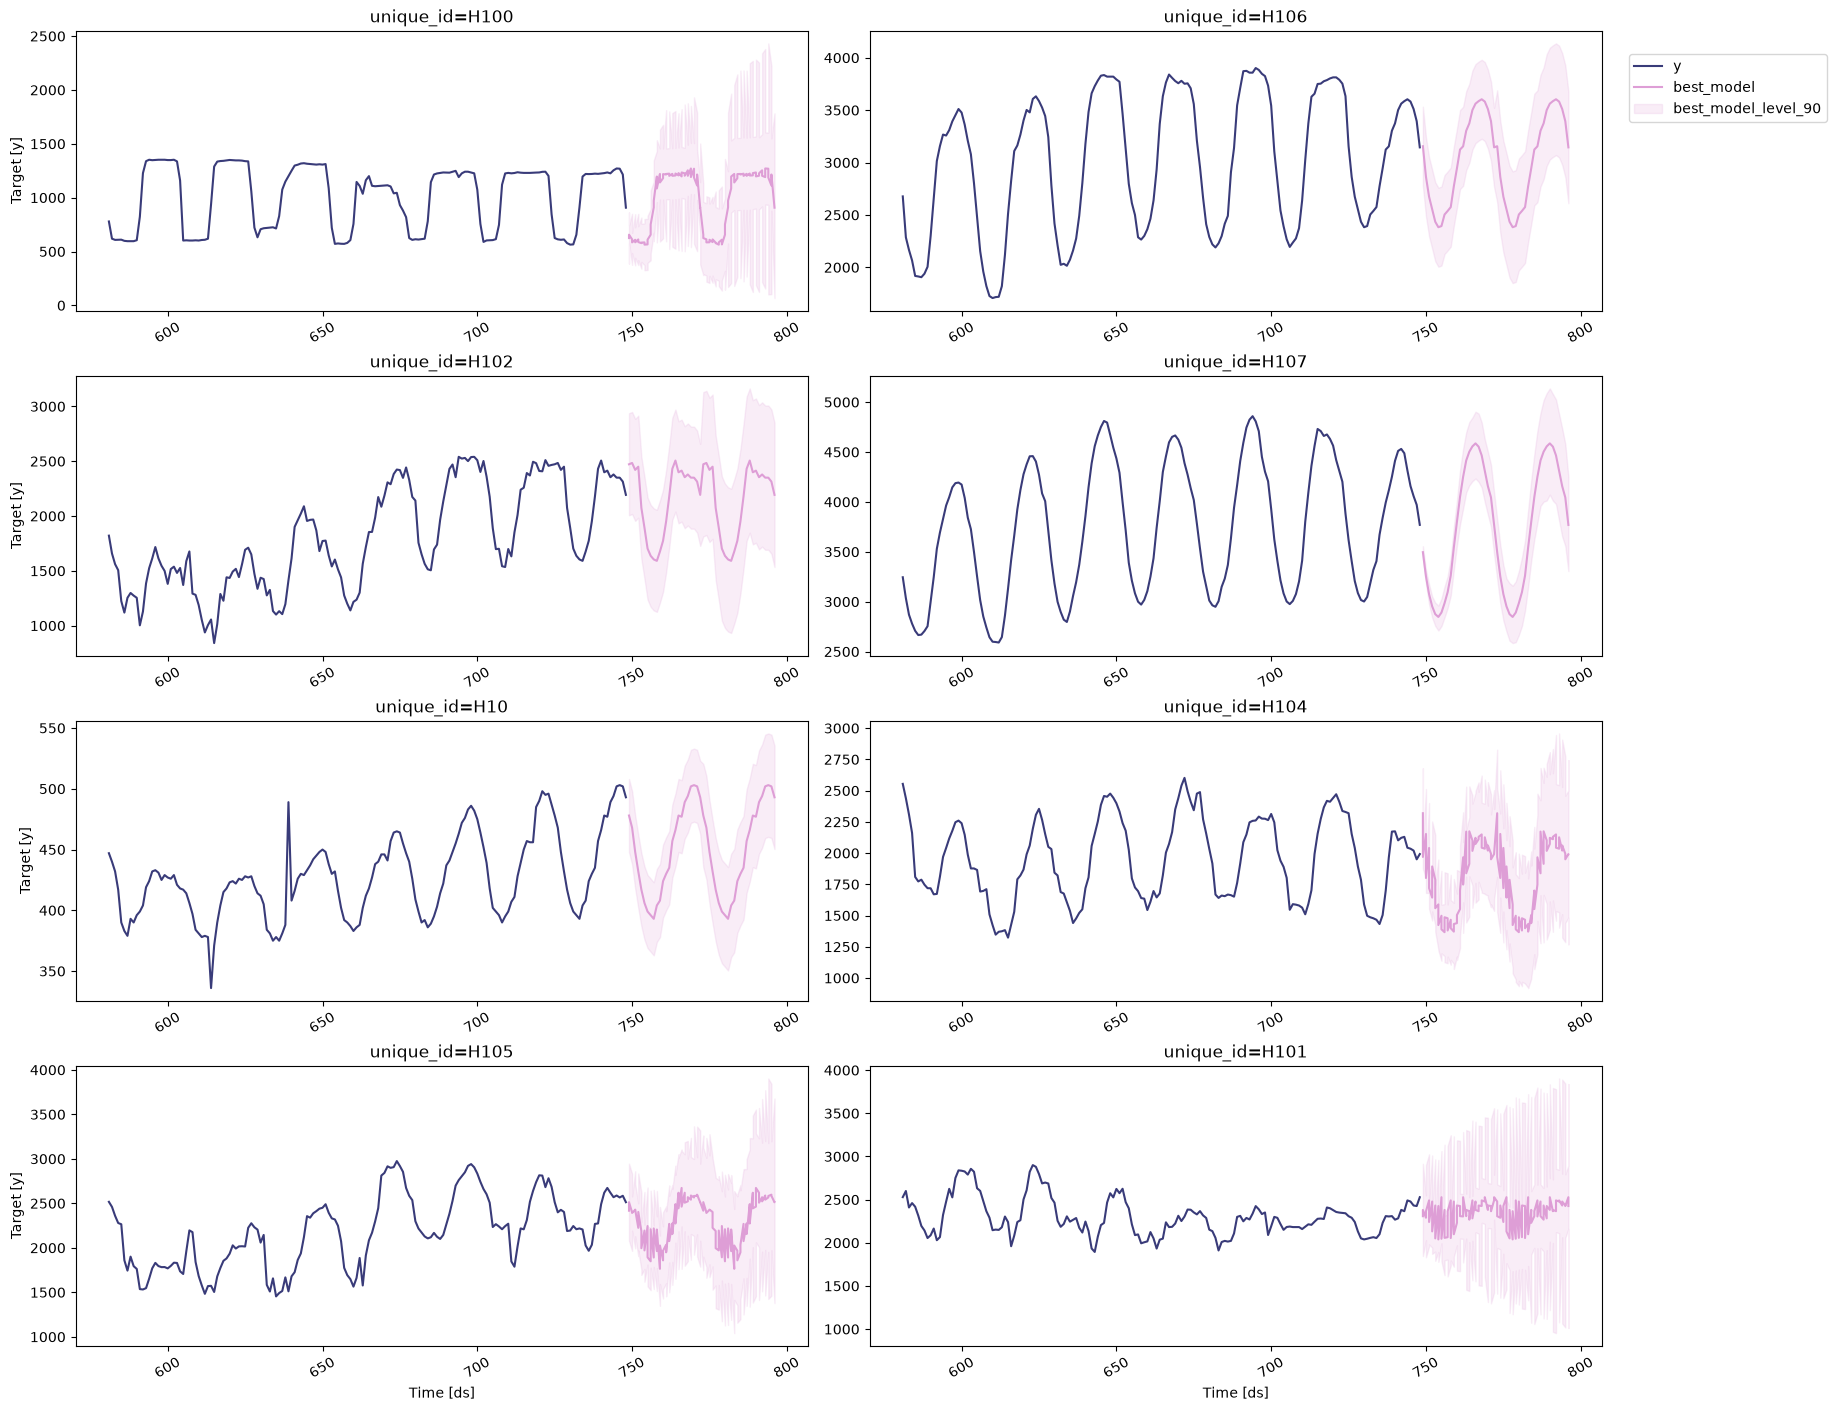

In [42]:
# plots the results
sf.plot(Y_df, prod_forecasts_df, level=[90])